In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

from hfp_tools import hfp_quantile

Load data

From database db_stocks_SP500/SPX we upload the realized values of the S&P 500 index

In [2]:
# Find the ROOT & DATA path
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

In [3]:
# ---------------------------------------------------------------------------
# Load data
# ---------------------------------------------------------------------------
CSV_PATH = Path(DATA_DIR,"/SPX.csv").expanduser()
t_bar = 1799   # number of returns (uses the last t_bar + 1 closes)

In [4]:
def load_spx(csv_path=CSV_PATH, n_prices=t_bar + 1):
    """Daily S&P 500 closes as a pd.Series indexed by date."""
    if csv_path.exists():
        df = pd.read_csv(csv_path, parse_dates=["date"])
        close = df.set_index("date")["SPX_close"]
    else:
        import yfinance as yf  # pip install yfinance
        close = yf.download("^GSPC", period="10y", auto_adjust=True,
                            progress=False)["Close"].squeeze()
    return close.dropna().sort_index().iloc[-n_prices:]


v = load_spx()


1. Compute past realizations of S&P 500 compounded return

In [5]:
# ---------------------------------------------------------------------------
# 1. Compounded (log) returns  eps_t = ln(v_t / v_{t-1})
# ---------------------------------------------------------------------------
eps = np.diff(np.log(v.to_numpy()))   # length t_bar
dates = v.index[1:]                   # date of each return
t_bar = len(eps)

2. Compute time series of EWM and EWM standard deviation

In [6]:
# ---------------------------------------------------------------------------
# 2. EWMA (17.39) and EWM standard deviation (17.43)
# ---------------------------------------------------------------------------
w = 200        # trailing window
tau_hl = 25    # half-life

# weights for one window, oldest first: e^{-ln2/tau * i}, i = w-1 ... 0
p_w = np.exp(-np.log(2) / tau_hl * np.arange(w))[::-1]
p_w = p_w / p_w.sum()                 # divide by gamma_w so they sum to 1

windows = sliding_window_view(eps, w)  # shape (t_bar - w + 1, w); row k ends at eps[k + w - 1]
ewma = windows @ p_w                               # sum_i p_i x_{t-i}
ewm_sd = np.sqrt((windows**2) @ p_w - ewma**2)     # sqrt(ewma(x^2) - ewma(x)^2)

3. Set exponential decay probabilities with most recent observation as a target and compute
time series of EWM quantile.

In [7]:
# ---------------------------------------------------------------------------
# 3. EWM c-quantile (17.44): the rolling, recency-weighted historical VaR level
# ---------------------------------------------------------------------------
c = 0.05
ewm_q = np.array([hfp_quantile(win, p_w, c) for win in windows])

window_dates = dates[w - 1:]          # each statistic is dated at its window's last day
eps_plot = eps[w - 1:]

4. Extra

In [8]:
# ---------------------------------------------------------------------------
# 4. Extra: the recursive form (17.42) is exactly pandas' ewm(halflife=...)
# ---------------------------------------------------------------------------
# lambda = e^{-ln2/tau_hl};  ewma_t = lambda * ewma_{t-1} + (1 - lambda) * x_t
ewma_recursive = pd.Series(eps).ewm(halflife=tau_hl, adjust=True).mean().to_numpy()[w - 1:]
print(f"Latest EWMA (window w={w}):        {ewma[-1]: .6f}")
print(f"Latest EWMA (pandas, infinite w):  {ewma_recursive[-1]: .6f}")
print(f"Max gap over the sample:           {np.max(np.abs(ewma - ewma_recursive)):.2e}")
print(f"Latest EWM sd (daily):             {ewm_sd[-1]:.4%}")
print(f"Latest EWM 5% quantile (daily):    {ewm_q[-1]:.4%}")


Latest EWMA (window w=200):        -0.000004
Latest EWMA (pandas, infinite w):  -0.000001
Max gap over the sample:           3.75e-05
Latest EWM sd (daily):             1.0840%
Latest EWM 5% quantile (daily):    -1.5785%


5. Plots

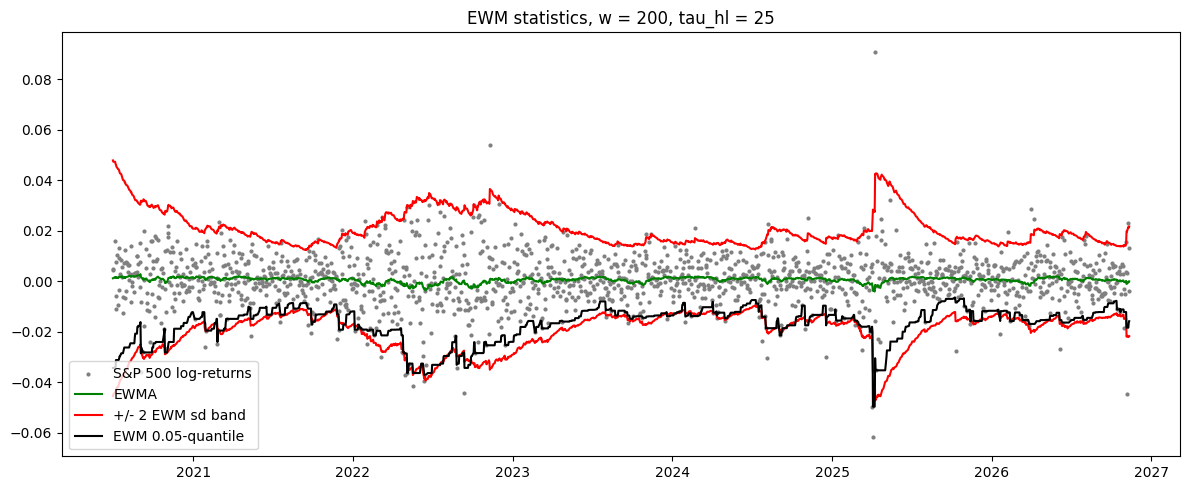

In [10]:
# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(window_dates, eps_plot, s=4, color="grey", label="S&P 500 log-returns")
ax.plot(window_dates, ewma, color="green", label="EWMA")
ax.plot(window_dates, ewma + 2 * ewm_sd, color="red", label="+/- 2 EWM sd band")
ax.plot(window_dates, ewma - 2 * ewm_sd, color="red")
ax.plot(window_dates, ewm_q, color="black", label=f"EWM {c:.2f}-quantile")
ax.set_title(f"EWM statistics, w = {w}, tau_hl = {tau_hl}")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()